In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [46]:
cluster =  pd.read_csv("grova2.csv",header = None)

In [47]:
cluster.columns = ["X","Y","Vx","Vy","Vz"]

In [48]:
cluster

,X,Y,Vx,Vy,Vz
0,15.29,27.30,3.65,1.88,1.93
1,22.51,8.02,3.79,1.39,1.60
2,17.16,15.07,0.14,0.29,3.74
3,58.72,31.59,3.33,1.70,1.69
4,63.48,28.91,1.09,2.80,2.21
...,...,...,...,...,...
10995,37.48,42.22,3.67,3.68,3.66
10996,38.04,33.95,3.24,4.58,4.21
10997,30.26,48.87,4.71,4.71,4.66
10998,41.28,39.03,2.85,4.04,4.45


In [49]:
X = cluster["X"]
Y = cluster["Y"]
Vx = cluster["Vx"]
Vy = cluster["Vy"]
Vz = cluster["Vz"]

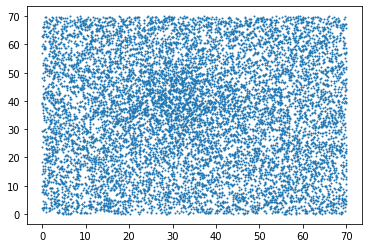

In [50]:
plt.scatter(cluster["X"],cluster["Y"], s = 1)

(0.0, 157.0)

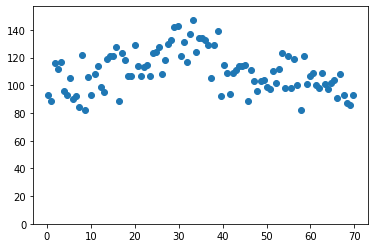

In [51]:
# ეს არ დაგვეხმარა არაფერში რადგან ბევრი ვარსკვლავია საშუალოს გასწვრივ, რომელიც არ ემთხვევა თავისთავად იმ ამპლიტუდას რომელსაც ვხედავთ. 
bins = 100

uniform_hist_X = np.histogram(X, bins)
edges = uniform_hist_X[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_X[0])
plt.ylim(0,max(uniform_hist_X[0]) + 10)

(0.0, 159.0)

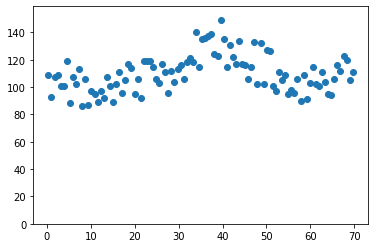

In [52]:
# იგივე Y-ზეც. 
uniform_hist_Y = np.histogram(Y, bins)
edges1 = uniform_hist_Y[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_Y[0])
plt.ylim(0,max(uniform_hist_Y[0]) + 10)

In [53]:
def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2/(2*sigma**2))

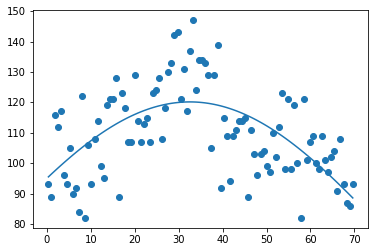

In [54]:
# ამ ვარსკვლავების სიბევრის გამო, ვერ აღიქვამს სწორად პიკს. ცოტათი გადახარა, თუმცა ჩემთვის არაფრისმომცემია.
popt, pcov = curve_fit(gauss, centers, uniform_hist_X[0], p0=[uniform_hist_X[0].max(), X.mean(), X.std()])
plt.scatter(centers, uniform_hist_X[0])
plt.plot(centers, gauss(centers, *popt))

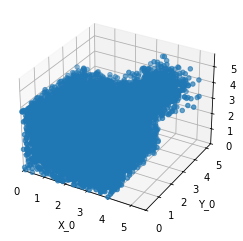

In [55]:
# გადავწყვიტე სიჩქარებიის მიხედვით გავფლიტრო ჯერ. 
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

X_0, Y_0, Z_0 = [0, 0], [0, 0], [0, 0]
ax.set_xlim([0, max(Vx)])
ax.set_ylim([0, max(Vy)])
ax.set_zlim([0, max(Vz)])
ax.set_xlabel('X_0')
ax.set_ylabel('Y_0')
ax.set_zlabel('Z_0')

ax.scatter(Vx,Vy,Vz)

In [56]:
cluster.describe()

,X,Y,Vx,Vy,Vz
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000
mean,34.607379,35.480471,2.175928,2.180388,2.166670
std,19.498853,19.717705,1.246390,1.244227,1.233207
min,0.000000,0.010000,0.000000,0.000000,0.000000
25%,18.380000,19.017500,1.090000,1.100000,1.117500
50%,33.975000,36.040000,2.220000,2.210000,2.180000
75%,51.202500,51.612500,3.270000,3.270000,3.250000
max,69.990000,70.000000,5.650000,5.390000,5.790000


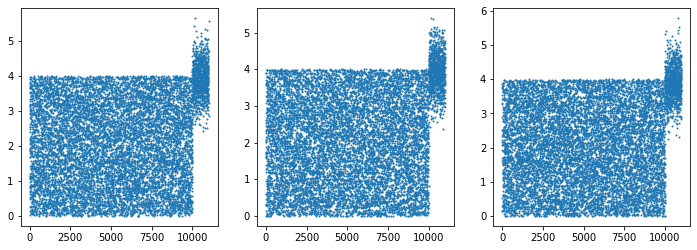

In [57]:
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.scatter(cluster.index,Vx, s = 1)
ax2.scatter(cluster.index,Vy, s = 1)
ax3.scatter(cluster.index,Vz, s = 1)


In [58]:
# როგორც ჩანს, გროვის ვარსკვლავების სიჩქარე ვარირებს დაახლოებით სამსა და ხუთს შორის.
# რახან სამსა და ოთხს შორის სხვა ფონის ვარსკვლავებიც არიან, მე ჯერ გამოვყოფ იმათ, რომელთა სიჩქარეები არის 4-ზე მეტი. 

In [59]:
# განზოგადებისთვის ვიპოვი მოდას და გამოვიყენებ მას გამოსაყოფად.
# გადასამოწმებლად
Vx.mode()

0    3.94
Name: Vx, dtype: float64

In [60]:
# აქ ვსვამ ხელით
Vx_cutoff = float(Vx.mode())
Vy_cutoff = float(Vy.mode())
Vz_cutoff = float(Vz.mode())

In [97]:
# ეს მომავლისთვის, როცა დამჭირდება იმ დამატებითი ვარსკვლავებიც პოვნაც, რომლებიც არიან სამსა და ხუთს შორის და ერევიან ბექგრაუნდ ვარსკვლავებს. 
Vx_cutoff_second = 3
Vy_cutoff_second = 3
Vz_cutoff_second = 3

In [61]:
final_cluster = cluster[(cluster["Vx"] >= Vx_cutoff) & (cluster["Vy"] >= Vy_cutoff) & (cluster["Vz"] >= Vz_cutoff)]
final_cluster

,X,Y,Vx,Vy,Vz
273,40.55,29.46,3.96,3.84,3.93
10000,20.76,39.09,4.02,4.38,3.89
10003,24.05,40.39,4.03,3.79,4.39
10004,26.93,57.19,4.11,3.90,3.91
10009,34.03,39.54,4.21,4.01,4.37
...,...,...,...,...,...
10959,41.10,31.28,4.65,4.31,4.43
10968,31.27,35.03,4.49,4.30,4.26
10982,30.02,41.71,4.56,4.05,3.93
10985,34.94,52.00,4.10,4.55,3.84


In [62]:
X_cluster = final_cluster["X"]
Y_cluster = final_cluster["Y"]

In [63]:
final_cluster.describe()

,X,Y,Vx,Vy,Vz
count,185.000000,185.000000,185.000000,185.000000,185.000000
mean,30.861568,39.951027,4.323676,4.185351,4.274703
std,9.072169,9.266000,0.287524,0.372055,0.338730
min,6.330000,15.050000,3.940000,3.630000,3.840000
25%,25.350000,33.940000,4.100000,3.900000,4.020000
50%,31.090000,39.460000,4.260000,4.110000,4.220000
75%,36.180000,47.130000,4.500000,4.450000,4.500000
max,62.080000,63.430000,5.330000,5.150000,5.790000


In [64]:
#გავფილტრე სიჩქარეების მიხედვით. თუმცა ახლა კიდევ გავფილტრავ კოორდინატების მიხედვით.

(0.0, 20.0)

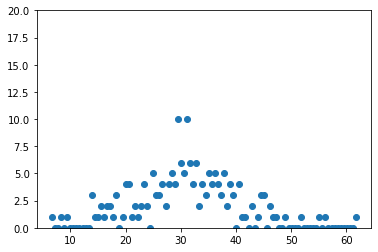

In [65]:
bins = 100

uniform_hist_X = np.histogram(X_cluster, bins)
edges = uniform_hist_X[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_X[0])
plt.ylim(0,max(uniform_hist_X[0]) + 10)

(0.0, 18.0)

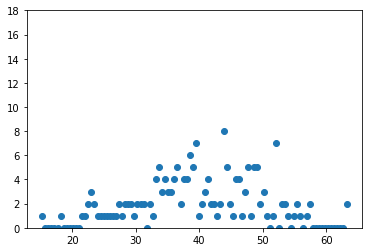

In [66]:
uniform_hist_Y = np.histogram(Y_cluster, bins)
edges1 = uniform_hist_Y[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_Y[0])
plt.ylim(0,max(uniform_hist_Y[0]) + 10)

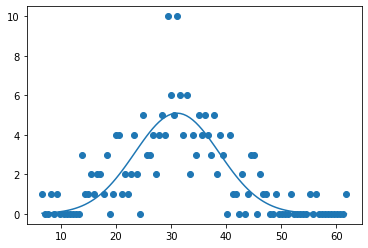

In [67]:
popt, pcov = curve_fit(gauss, centers, uniform_hist_X[0], p0=[uniform_hist_X[0].max(), X_cluster.mean(), X_cluster.std()])
plt.scatter(centers, uniform_hist_X[0])
plt.plot(centers, gauss(centers, *popt))

In [68]:
x_center = popt[1]

In [69]:
residuals = uniform_hist_X[0] - gauss(centers, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_X[0] - uniform_hist_X[0].mean())**2)
r2 = 1 - ss_res / ss_tot
r2

0.640309550717038

0.45626817895689487

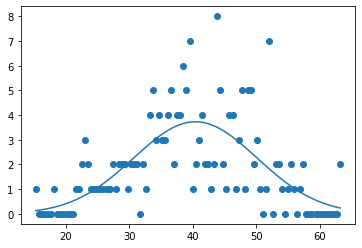

In [70]:
popt, pcov = curve_fit(gauss, centers1, uniform_hist_Y[0], p0=[uniform_hist_Y[0].max(), Y_cluster.mean(), Y_cluster.std()])
plt.scatter(centers1, uniform_hist_Y[0])
plt.plot(centers1, gauss(centers1, *popt))
residuals = uniform_hist_Y[0] - gauss(centers1, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_Y[0] - uniform_hist_Y[0].mean())**2)
r2_y = 1 - ss_res / ss_tot
r2_y

In [71]:
y_center = popt[1]

In [72]:
print(x_center, y_center)

31.083030425814556 40.40324234314584


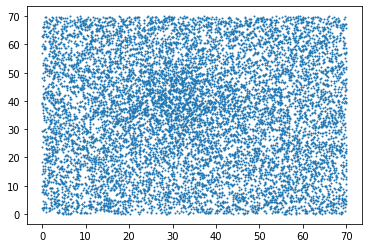

In [76]:
plt.scatter(X,Y, s = 1)

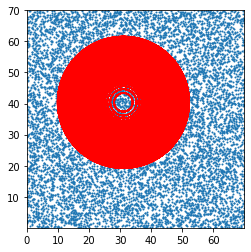

In [106]:
n = final_cluster.shape[0]

r = 3
n_circ = 50
t = np.linspace(-10*np.pi,10*np.pi,300)

final_radius = r*np.sqrt(50)
plt.scatter(X, Y, s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(X.min(), X.max())
plt.ylim(Y.min(), Y.max())
plt.gca().set_aspect("equal")

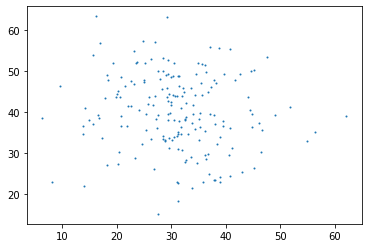

In [91]:
plt.scatter(X_cluster, Y_cluster, s = 1)

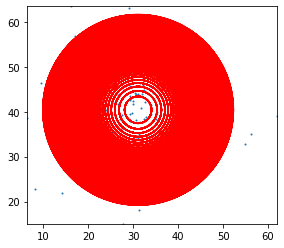

In [92]:
t = np.linspace(-10*np.pi,10*np.pi,300)

plt.scatter(X_cluster, Y_cluster, s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(X_cluster.min(), X_cluster.max())
plt.ylim(Y_cluster.min(), Y_cluster.max())
plt.gca().set_aspect("equal")

In [124]:
counts = [0] * n_circ
selected = []   # row positions of stars inside the circles

for i in range(n_circ):
    for j in range(n):
        d2 = (X_cluster.iloc[j] - x_center)**2 + (Y_cluster.iloc[j] - y_center)**2
        if (r*np.sqrt(i))**2 < d2 <= (r*np.sqrt(i+1))**2:
            counts[i] += 1
            selected.append(j)

final_coordinates = final_cluster.iloc[selected]

In [94]:
sum(counts)

173

In [ ]:
n_all = cluster.shape[0]
counts_full = [0] * n_circ

for i in range(n_circ):
    for j in range(n_all):
        if (r*np.sqrt(i))**2<(X.iloc[j]-x_center)**2 + (Y.iloc[j]-y_center)**2<=(r*np.sqrt(i+1))**2:
            counts_full[i] = counts_full[i] + 1

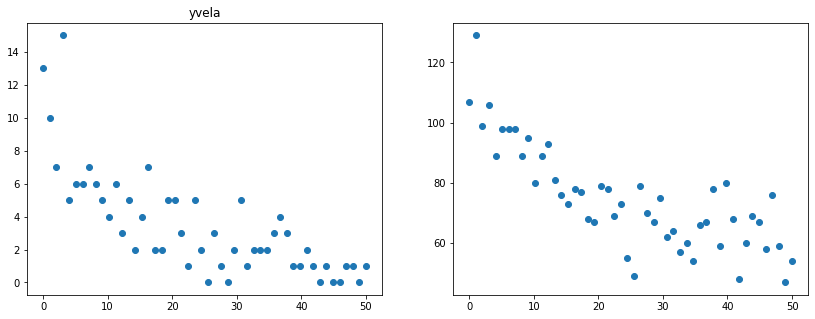

In [96]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize = (14,5))
ax1.scatter(np.linspace(0,n_circ,n_circ),counts)
ax1.set_title("clusteri")
ax2.scatter(np.linspace(0,n_circ,n_circ),counts_full)
ax1.set_title("yvela")

plt.show()

In [98]:
# ახლა უნდა დავხაზო ყველა ის ვარსკვლავი, რომლის სიჩქარეები აღემატება სამს
additional_cluster = cluster[(cluster["Vx"] >= Vx_cutoff_second) & (cluster["Vx"] < Vx_cutoff) & (cluster["Vy"] >= Vy_cutoff_second) & (cluster["Vy"] < Vy_cutoff) & (cluster["Vz"] >= Vz_cutoff_second) & (cluster["Vx"] < Vz_cutoff)]

In [103]:
X_additional = additional_cluster["X"]
Y_additional = additional_cluster["Y"]

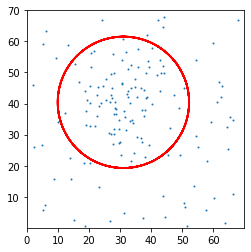

In [109]:
plt.scatter(X_additional, Y_additional, s = 1)
plt.plot(x_center + final_radius*np.cos(t), y_center + final_radius*np.sin(t),c = "r")
plt.xlim(X.min(), X.max())
plt.ylim(Y.min(), Y.max())
plt.gca().set_aspect("equal")

In [127]:
n_add = additional_cluster.shape[0]
counts_add = [0] * n_circ
selected_add = []   # row positions of additional stars inside the circles

for i in range(n_circ):
    for j in range(n_add):
        d2 = (X_additional.iloc[j] - x_center)**2 + (Y_additional.iloc[j] - y_center)**2
        if (r*np.sqrt(i))**2 < d2 <= (r*np.sqrt(i+1))**2:
            counts_add[i] += 1
            selected_add.append(j)

final_additional = additional_cluster.iloc[selected_add]


In [128]:
all_cluster_stars = pd.concat([
    final_coordinates.assign(group="main"),
    final_additional.assign(group="additional"),
])


In [141]:
all_cluster_stars = all_cluster_stars.sort_index()

In [142]:
all_cluster_stars.head(20)

,X,Y,Vx,Vy,Vz,group
273,40.55,29.46,3.96,3.84,3.93,main
2356,27.05,49.39,3.29,3.19,3.80,additional
3653,27.59,27.12,3.13,3.54,3.33,additional
3678,30.64,46.28,3.05,3.03,3.99,additional
4051,35.77,57.71,3.12,3.33,3.04,additional
4260,30.32,23.36,3.81,3.31,3.76,additional
4272,15.66,52.70,3.63,3.37,3.19,additional
4343,50.47,44.87,3.83,3.19,3.75,additional
4841,33.44,52.27,3.19,3.39,3.02,additional
6550,21.64,56.85,3.75,3.00,3.69,additional


In [143]:
all_cluster_stars

,X,Y,Vx,Vy,Vz,group
273,40.55,29.46,3.96,3.84,3.93,main
2356,27.05,49.39,3.29,3.19,3.80,additional
3653,27.59,27.12,3.13,3.54,3.33,additional
3678,30.64,46.28,3.05,3.03,3.99,additional
4051,35.77,57.71,3.12,3.33,3.04,additional
...,...,...,...,...,...,...
10979,31.04,60.84,3.48,3.37,3.42,additional
10980,31.14,37.66,3.26,3.56,4.16,additional
10982,30.02,41.71,4.56,4.05,3.93,main
10985,34.94,52.00,4.10,4.55,3.84,main
